# Laboratorio #2 — Parte A: Transfer Learning con PyTorch

**Estudiante:** Juan Esteban Orrego 2
**Curso:** Redes Neuronales y Aprendizaje Profundo — Universidad EAFIT
**Dataset:** Kaggle *Dog vs Cat Images Data* (`kunalgupta2616/dog-vs-cat-images-data`)

Modelos desarrollados:
- **M1** — VGG-16 como extractor de features fijo + clasificador lineal.
- **M2** — VGG-16 con clasificador reemplazado y fine-tuning completo.
- **M3** — ResNet-18 adaptado a Cats vs. Dogs.

Este notebook es autocontenido: incluye el código completo ejecutado y las respuestas
a todas las preguntas en celdas Markdown.


## 0. Imports y configuración

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.tensorboard import SummaryWriter
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchinfo import summary
import matplotlib.pyplot as plt
import numpy as np
import os
from PIL import Image
import glob
import time

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Usando device: {device}')
if device == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')


Usando device: cuda
GPU: NVIDIA GeForce RTX 3060


## 1. Funciones auxiliares

Utilidades que usaremos a lo largo del notebook: verificación del dataset,
visualización de muestras y el loop de entrenamiento con logging a TensorBoard.


In [2]:
def check_image_dir(pattern):
    """Elimina imágenes corruptas que coincidan con el patrón glob."""
    removed = 0
    for fname in glob.glob(pattern):
        try:
            img = Image.open(fname)
            img.verify()
        except Exception:
            print(f'Eliminando archivo corrupto: {fname}')
            try:
                os.remove(fname)
            except OSError:
                pass
            removed += 1
    print(f'{pattern}: {removed} archivos eliminados')


def display_dataset(dataset, n=10):
    """Muestra n imágenes aleatorias del dataset con su etiqueta."""
    indices = np.random.choice(len(dataset), n, replace=False)
    fig, axes = plt.subplots(2, n // 2, figsize=(15, 5))
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    for ax, idx in zip(axes.flat, indices):
        img, label = dataset[idx]
        img = (img * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
        ax.imshow(img)
        title = dataset.classes[label] if hasattr(dataset, 'classes') else str(label)
        ax.set_title(title, fontsize=9)
        ax.axis('off')
    plt.tight_layout()
    plt.show()


def train_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(X)
        loss = loss_fn(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
        total += len(y)
    return total_loss / total, correct / total


def eval_epoch(model, loader, loss_fn):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            out = model(X)
            loss = loss_fn(out, y)
            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
    return total_loss / total, correct / total


def train(model, train_loader, test_loader, loss_fn=None, optimizer=None,
          epochs=5, lr=1e-3, writer=None, tag=''):
    if loss_fn is None:
        loss_fn = nn.CrossEntropyLoss()
    if optimizer is None:
        optimizer = optim.Adam(
            filter(lambda p: p.requires_grad, model.parameters()), lr=lr
        )
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_epoch(model, train_loader, optimizer, loss_fn)
        va_loss, va_acc = eval_epoch(model, test_loader, loss_fn)
        dt = time.time() - t0
        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc)
        if writer:
            writer.add_scalars(f'{tag}/Loss', {'train': tr_loss, 'val': va_loss}, epoch)
            writer.add_scalars(f'{tag}/Acc',  {'train': tr_acc,  'val': va_acc},  epoch)
        print(f'Epoch {epoch:02d}/{epochs} | '
              f'train loss {tr_loss:.4f} acc {tr_acc:.4f} | '
              f'val loss {va_loss:.4f} acc {va_acc:.4f} | {dt:.1f}s')
    return history


def plot_results(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(history['train_loss'], label='train')
    ax1.plot(history['val_loss'],   label='val')
    ax1.set_title('Loss'); ax1.legend()
    ax2.plot(history['train_acc'], label='train')
    ax2.plot(history['val_acc'],   label='val')
    ax2.set_title('Accuracy'); ax2.legend()
    plt.tight_layout()
    plt.show()

print('Funciones auxiliares definidas')


Funciones auxiliares definidas


## 2. Dataset: Cats vs. Dogs

Usamos el dataset de Kaggle [Dog vs Cat Images Data](https://www.kaggle.com/datasets/kunalgupta2616/dog-vs-cat-images-data).
Según su documentación, es una mejora del dataset de la competencia oficial *Dogs vs Cats* de Kaggle,
reorganizado jerárquicamente en `train` (25 000), `validation` (8 000) y `test` (12 500).

El dataset ya fue descargado y extraído en `data/dogcat/`. La estructura real es:

```
data/dogcat/
├── train/        (cats: 12500, dogs: 12500)
├── validation/   (cats: 4000,  dogs: 4000)
└── test1/test1/  (12500 imágenes sin etiqueta)
```

> **Nota:** las subcarpetas de clase son minúsculas (`cats`, `dogs`). `ImageFolder` infiere
> las clases como `['cats', 'dogs']` con índices `{cats: 0, dogs: 1}`.


In [3]:
# Rutas del dataset Kaggle (ya descargado y extraído)
TRAIN_DIR = 'data/dogcat/train'
VAL_DIR   = 'data/dogcat/validation'

assert os.path.isdir(TRAIN_DIR), f'No existe {TRAIN_DIR}'
assert os.path.isdir(VAL_DIR),   f'No existe {VAL_DIR}'
print('train:', os.listdir(TRAIN_DIR))
print('validation:', os.listdir(VAL_DIR))


train: ['cats', 'dogs']
validation: ['cats', 'dogs']


Eliminamos posibles imágenes corruptas antes de construir el `Dataset`:

In [4]:
check_image_dir(os.path.join(TRAIN_DIR, 'cats', '*.jpg'))
check_image_dir(os.path.join(TRAIN_DIR, 'dogs', '*.jpg'))
check_image_dir(os.path.join(VAL_DIR,   'cats', '*.jpg'))
check_image_dir(os.path.join(VAL_DIR,   'dogs', '*.jpg'))


data/dogcat/train\cats\*.jpg: 0 archivos eliminados


data/dogcat/train\dogs\*.jpg: 0 archivos eliminados


data/dogcat/validation\cats\*.jpg: 0 archivos eliminados


data/dogcat/validation\dogs\*.jpg: 0 archivos eliminados


### Transforms y normalización — Actividad 1

Los modelos preentrenados en ImageNet esperan imágenes de **224×224** normalizadas con:

```
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]
```

El pipeline sigue el orden pedido: **Resize(256) → CenterCrop(224) → ToTensor → Normalize**.


Train: 25000 imágenes | Clases: ['cats', 'dogs']
Validation: 8000 imágenes | Clases: ['cats', 'dogs']


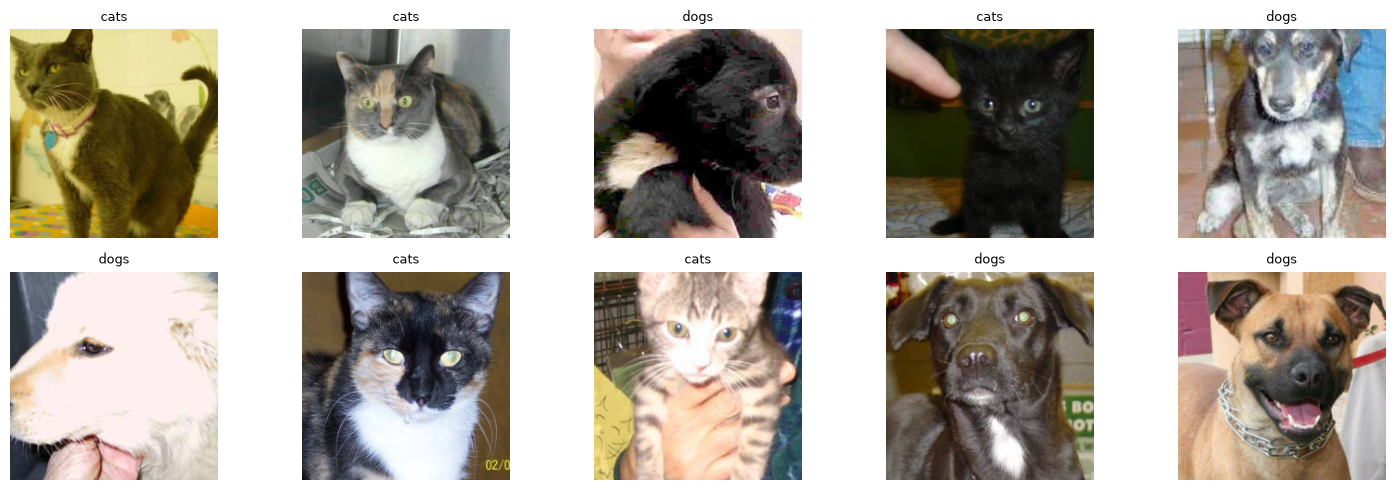

In [5]:
std_normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std =[0.229, 0.224, 0.225]
)

# Pipeline de preprocesamiento (TODO 1 resuelto)
trans = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    std_normalize
])

assert trans is not None, 'Debes definir el pipeline de transforms'

# Dataset completo = train + validation del dataset de Kaggle
train_full = torchvision.datasets.ImageFolder(TRAIN_DIR, transform=trans)
val_full   = torchvision.datasets.ImageFolder(VAL_DIR,   transform=trans)
print(f'Train: {len(train_full)} imágenes | Clases: {train_full.classes}')
print(f'Validation: {len(val_full)} imágenes | Clases: {val_full.classes}')

# Para compatibilidad con el resto del notebook usamos `dataset` = train completo
dataset = train_full
display_dataset(dataset)


**Pregunta (Actividad 1): ¿De dónde vienen esos valores de media y std? ¿Por qué es importante usarlos si vas a cargar pesos preentrenados?**

Los valores `mean=[0.485, 0.456, 0.406]` y `std=[0.229, 0.224, 0.225]` son la **media y desviación estándar por canal (R, G, B)** calculadas sobre todas las imágenes del conjunto de entrenamiento de **ImageNet** (~1.28 millones de imágenes). Es decir, se obtuvieron empíricamente promediando los valores de píxel (en el rango [0, 1]) de cada canal a lo largo de todo el dataset.

Es importante usarlos porque los pesos preentrenados fueron **aprendidos sobre entradas normalizadas con esas estadísticas exactas**. La primera capa convolucional y todas las siguientes "esperan" recibir datos centrados y escalados de esa forma. Si normalizáramos con otros valores (o no normalizáramos), la distribución de las activaciones de entrada no coincidiría con la que vio la red durante su preentrenamiento, y los filtros producirían representaciones distorsionadas, degradando el rendimiento del transfer learning. En resumen: para que el conocimiento transferido sea válido, la entrada debe estar en el mismo "espacio" estadístico que el usado al entrenar los pesos originales.


## 3. Modelos preentrenados — Actividad 2

Cargamos VGG-16 con pesos de ImageNet usando la **API moderna** de torchvision
(`weights=VGG16_Weights.DEFAULT`) y hacemos una inferencia sobre una imagen de muestra.
Verificamos que la salida tenga shape `[1, 1000]`.


In [6]:
vgg = torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.DEFAULT)
vgg = vgg.to(device)

sample_image, _ = dataset[0]
sample_image = sample_image.unsqueeze(0).to(device)

with torch.no_grad():
    res = vgg(sample_image)

print(f'Shape de salida: {res.shape}')  # [1, 1000]
assert tuple(res.shape) == (1, 1000), 'La salida debe ser [1, 1000]'
print(f'Clase predicha (índice ImageNet): {res[0].argmax().item()}')


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to C:\Users\PC/.cache\torch\hub\checkpoints\vgg16-397923af.pth


  0%|          | 0.00/528M [00:00<?, ?B/s]

  0%|          | 128k/528M [00:00<09:21, 986kB/s]

  0%|          | 384k/528M [00:00<05:37, 1.64MB/s]

  0%|          | 1.50M/528M [00:00<01:48, 5.11MB/s]

...

 99%|█████████▊| 521M/528M [00:17<00:00, 33.8MB/s]

 99%|█████████▉| 524M/528M [00:17<00:00, 33.4MB/s]

100%|█████████▉| 527M/528M [00:17<00:00, 33.2MB/s]

100%|██████████| 528M/528M [00:17<00:00, 32.1MB/s]

Shape de salida: torch.Size([1, 1000])
Clase predicha (índice ImageNet): 282


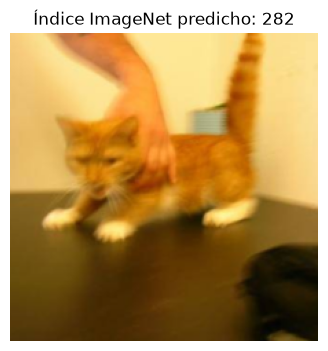

In [7]:
# Visualizar la imagen de muestra
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

img_show = (sample_image.squeeze(0).cpu() * std + mean).clamp(0, 1)
img_show = img_show.permute(1, 2, 0).numpy()

plt.figure(figsize=(4, 4))
plt.imshow(img_show)
plt.title(f'Índice ImageNet predicho: {res[0].argmax().item()}')
plt.axis('off')
plt.show()


Descargamos el mapeo de clases de ImageNet para mostrar el **nombre** de la clase predicha:

In [8]:
import json, requests

try:
    class_map = json.loads(
        requests.get('https://s3.amazonaws.com/deep-learning-models/image-models/imagenet_class_index.json',
                     timeout=30).text
    )
    class_map = {int(k): v for k, v in class_map.items()}
    pred_idx = res[0].argmax().item()
    print(f'Clase predicha: {class_map[pred_idx]}')
except Exception as e:
    print('No se pudo descargar el mapeo de clases ImageNet:', e)
    print('Índice predicho:', res[0].argmax().item())


Clase predicha: ['n02123159', 'tiger_cat']


### Arquitectura de VGG-16

Inspeccionamos la arquitectura completa con `torchinfo.summary`.
La red se divide en: `vgg.features` (extractor conv), `vgg.avgpool` (pooling adaptativo)
y `vgg.classifier` (capas densas 25088 → 1000).


In [9]:
summary(vgg, input_size=(1, 3, 224, 224))


Layer (type:depth-idx)                   Output Shape              Param #
VGG                                      [1, 1000]                 --
├─Sequential: 1-1                        [1, 512, 7, 7]            --
│    └─Conv2d: 2-1                       [1, 64, 224, 224]         1,792
│    └─ReLU: 2-2                         [1, 64, 224, 224]         --
│    └─Conv2d: 2-3                       [1, 64, 224, 224]         36,928
│    └─ReLU: 2-4                         [1, 64, 224, 224]         --
│    └─MaxPool2d: 2-5                    [1, 64, 112, 112]         --
│    └─Conv2d: 2-6                       [1, 128, 112, 112]        73,856
│    └─ReLU: 2-7                         [1, 128, 112, 112]        --
│    └─Conv2d: 2-8                       [1, 128, 112, 112]        147,584
│    └─ReLU: 2-9                         [1, 128, 112, 112]        --
│    └─MaxPool2d: 2-10                   [1, 128, 56, 56]          --
│    └─Conv2d: 2-11                      [1, 256, 56, 56]          29

**Pregunta (Actividad 2): ¿Cuántos parámetros tiene VGG-16 en total? ¿Qué hace la capa Dropout y por qué mejora la generalización? ¿Por qué la última capa tiene 1000 salidas?**

- **Parámetros totales de VGG-16:** aproximadamente **138 millones** (≈138.4 M). La gran mayoría está en las capas densas del clasificador (en particular la primera, `Linear(25088, 4096)`, que por sí sola tiene ~102 M parámetros). El `summary()` de arriba confirma la cifra exacta.

- **Dropout:** durante el entrenamiento, la capa `Dropout(p)` pone a cero aleatoriamente una fracción `p` de las activaciones de la capa anterior (en VGG, `p=0.5`). Esto es una técnica de **regularización**: impide que las neuronas se "co-adapten" (que dependan excesivamente unas de otras) y obliga a la red a aprender representaciones más robustas y redundantes. El resultado es que el modelo generaliza mejor a datos no vistos y es menos propenso al sobreajuste. En inferencia (`model.eval()`), Dropout se desactiva y escala las activaciones para mantener la esperanza.

- **1000 salidas:** la última capa lineal tiene 1000 unidades porque VGG-16 fue entrenada para clasificar las **1000 categorías** del reto ILSVRC de ImageNet. Cada salida corresponde al logit de una de esas 1000 clases.


## 4. Extracción de features — Actividad 2 (cont.)

Usamos `vgg.features` como extractor fijo. Primero visualizamos los mapas de activación
de la última capa convolucional (shape `[1, 512, 7, 7]`):


Shape del tensor de features: torch.Size([1, 512, 7, 7])


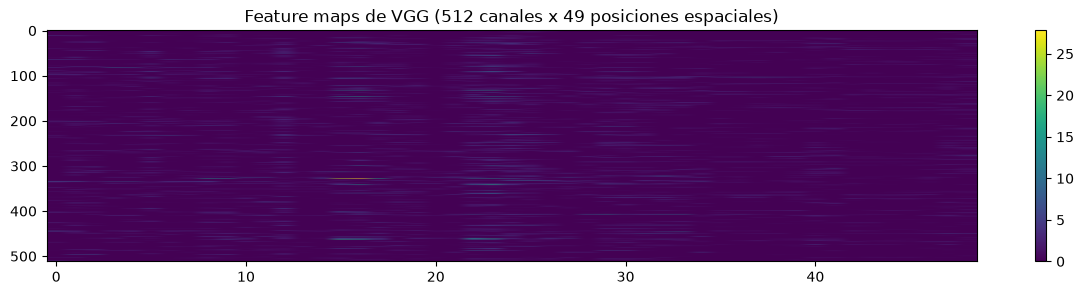

In [10]:
with torch.no_grad():
    feat = vgg.features(sample_image).cpu()

print(f'Shape del tensor de features: {feat.shape}')  # [1, 512, 7, 7]

plt.figure(figsize=(15, 3))
plt.imshow(feat.squeeze().view(512, -1).numpy(), aspect='auto', cmap='viridis')
plt.title('Feature maps de VGG (512 canales x 49 posiciones espaciales)')
plt.colorbar()
plt.show()


Pre-computamos los feature vectors de **800 imágenes** y los almacenamos en un tensor
de shape `[800, 512*7*7]` usando `torch.no_grad()` (requisito del PDF).

**TODO 2 resuelto:** inicializamos `feature_tensor` y `label_tensor`, y los llenamos dentro del loop.


In [11]:
bs  = 8
num = bs * 100  # 800 imágenes
dl  = torch.utils.data.DataLoader(dataset, batch_size=bs, shuffle=True, num_workers=0)

# TODO 2: inicialización de tensores
feature_tensor = torch.zeros(num, 512 * 7 * 7)  # [800, 25088]
label_tensor   = torch.zeros(num)               # [800]

i = 0
for x, l in dl:
    with torch.no_grad():
        feats = vgg.features(x.to(device))          # [bs, 512, 7, 7]
        feats = feats.view(x.size(0), -1).cpu()      # [bs, 25088]
    feature_tensor[i:i + x.size(0)] = feats
    label_tensor[i:i + x.size(0)]   = l
    i += bs
    print('.', end='')
    if i >= num:
        break

print(f'\nfeature_tensor: {feature_tensor.shape} | label_tensor: {label_tensor.shape}')
assert tuple(feature_tensor.shape) == (num, 512 * 7 * 7)


.

....

.

....

.....

...

.....

.....

.....

.....

.....
feature_tensor: torch.Size([800, 25088]) | label_tensor: torch.Size([800])


## 5. Clasificador lineal sobre features fijas — Actividad 3 (M1)

Entrenamos un clasificador de **una sola capa lineal** sobre los features pre-computados.
Esto es M1 en su primera etapa.

**Importante:** usar `nn.LogSoftmax()` al final junto con `CrossEntropyLoss` sería un error,
porque `CrossEntropyLoss` ya aplica (log-)softmax internamente. Por eso `net` es una sola
`nn.Linear` **sin activación final** (devuelve logits crudos).

**TODO 3 resuelto.**


Epoch 01/5 | train loss 0.2359 acc 0.9143 | val loss 0.1203 acc 0.9800 | 0.1s
Epoch 02/5 | train loss 0.0414 acc 0.9886 | val loss 0.0806 acc 0.9700 | 0.0s
Epoch 03/5 | train loss 0.0072 acc 0.9971 | val loss 0.0832 acc 0.9800 | 0.0s
Epoch 04/5 | train loss 0.0041 acc 0.9971 | val loss 0.0826 acc 0.9700 | 0.0s
Epoch 05/5 | train loss 0.0002 acc 1.0000 | val loss 0.0897 acc 0.9800 | 0.0s


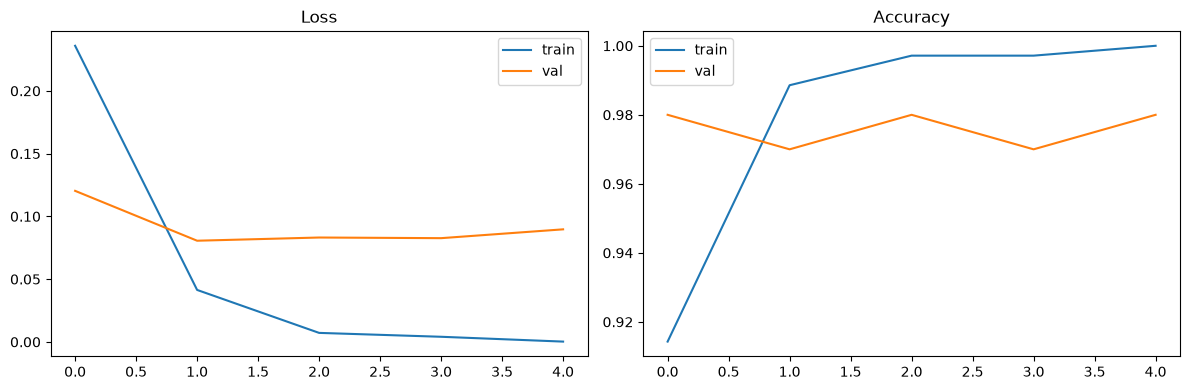

In [12]:
vgg_dataset = torch.utils.data.TensorDataset(
    feature_tensor,
    label_tensor.to(torch.long)
)
train_ds, test_ds = torch.utils.data.random_split(
    vgg_dataset, [700, 100],
    generator=torch.Generator().manual_seed(42)
)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=32)
test_loader  = torch.utils.data.DataLoader(test_ds,  batch_size=32)

# TODO 3: una sola capa lineal, sin activación final
net = nn.Sequential(nn.Linear(512 * 7 * 7, 2))
net = net.to(device)

writer  = SummaryWriter('runs/linear_classifier')
history = train(net, train_loader, test_loader, epochs=5, writer=writer, tag='linear')
writer.close()
plot_results(history)


**Pregunta (Actividad 3): ¿Cuál es la diferencia entre CrossEntropyLoss y NLLLoss + LogSoftmax? ¿Por qué combinarlos es un error?**

- `nn.LogSoftmax` aplica `log(softmax(x))` a los logits, produciendo log-probabilidades.
- `nn.NLLLoss` (Negative Log-Likelihood) toma log-probabilidades ya calculadas y devuelve la pérdida tomando el valor correspondiente a la clase correcta y negándolo.
- `nn.CrossEntropyLoss` es exactamente la **composición de ambas**: internamente aplica `LogSoftmax` y luego `NLLLoss`, en una sola operación numéricamente estable (usa el truco *log-sum-exp*).

Entonces, dos formas equivalentes de hacer lo mismo:
1. `red con LogSoftmax al final` + `NLLLoss`
2. `red que devuelve logits crudos` + `CrossEntropyLoss`

**Combinar `LogSoftmax` + `CrossEntropyLoss` es un error** porque se aplicaría el log-softmax **dos veces** (una en la red, otra dentro de `CrossEntropyLoss`). Eso distorsiona las "probabilidades", aplana los gradientes y produce un entrenamiento incorrecto. Por eso, si usamos `CrossEntropyLoss`, la red debe devolver **logits sin activación final**.


## 6. Transfer Learning: reemplazar el clasificador y congelar features — Actividad 4 (M2)

Recargamos VGG-16 limpio, reemplazamos `vgg.classifier` por una `nn.Linear(25088, 2)`
y congelamos todos los parámetros de `vgg.features` (`requires_grad = False`), de modo que
solo el nuevo clasificador se entrene.

**TODO 4 resuelto.**

> **Corrección de bug:** el `summary()` del código base usaba tamaño **244** en lugar de **224**.
> Aquí se usa correctamente `input_size=(1, 3, 224, 224)`.


In [13]:
# TODO 4a: cargar VGG-16 con pesos preentrenados (API moderna)
vgg = torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.DEFAULT)

# TODO 4b: reemplazar el clasificador por una sola capa Linear(25088, 2)
vgg.classifier = nn.Linear(25088, 2)

# TODO 4c: congelar los parámetros de vgg.features
for p in vgg.features.parameters():
    p.requires_grad = False

vgg = vgg.to(device)

# Verificación: solo el clasificador debe tener parámetros entrenables (~50k)
# BUG FIX: 224 (no 244)
summary(vgg, input_size=(1, 3, 224, 224))

trainable = sum(p.numel() for p in vgg.parameters() if p.requires_grad)
print(f'Parámetros entrenables: {trainable:,}')


Parámetros entrenables: 50,178


El summary muestra ~**50 000 parámetros entrenables** (solo los pesos de `Linear(25088, 2)`:
25088×2 + 2 = 50 178). Entrenamos **1 época sobre el dataset completo** (train 25 000 + val 8 000)
y guardamos el modelo.


Epoch 01/1 | train loss 0.2634 acc 0.9740 | val loss 0.1116 acc 0.9899 | 181.4s


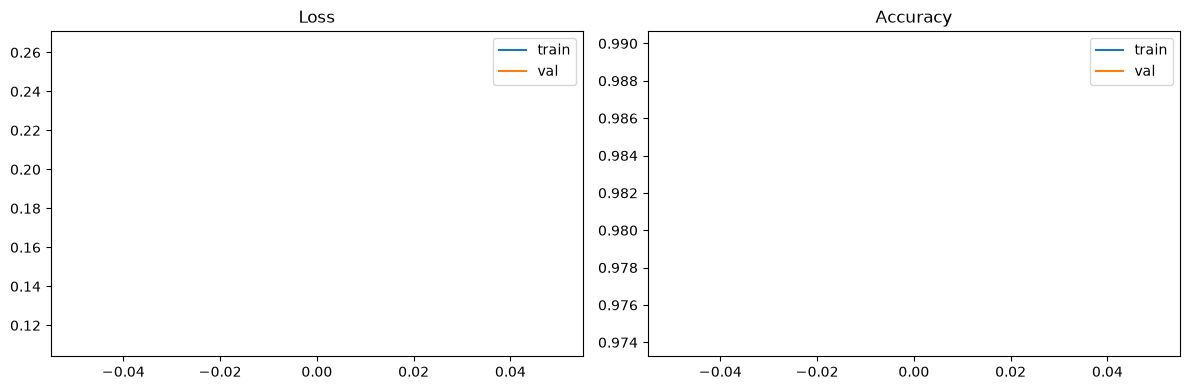

Modelo M2 (congelado) guardado


In [14]:
# Dataset completo: train (25000) para entrenar, validation (8000) para evaluar
trainset = train_full
testset  = val_full
train_loader = torch.utils.data.DataLoader(trainset, batch_size=16, shuffle=True,  num_workers=0, pin_memory=True)
test_loader  = torch.utils.data.DataLoader(testset,  batch_size=16, shuffle=False, num_workers=0, pin_memory=True)

os.makedirs('data', exist_ok=True)

writer = SummaryWriter('runs/transfer_frozen')
history_frozen = train(
    vgg, train_loader, test_loader,
    loss_fn=nn.CrossEntropyLoss(),
    epochs=1, lr=1e-3,
    writer=writer, tag='frozen'
)
writer.close()
plot_results(history_frozen)

torch.save(vgg.state_dict(), 'data/cats_dogs_weights.pth')
print('Modelo M2 (congelado) guardado')


**Pregunta (Actividad 4): ¿Por qué es importante congelar las capas convolucionales antes de entrenar el nuevo clasificador?**

Al reemplazar el clasificador por una capa `Linear` nueva, sus pesos están **inicializados aleatoriamente**. En las primeras iteraciones esta capa produce predicciones muy malas y, por lo tanto, **gradientes grandes**. Si las capas convolucionales estuvieran descongeladas, esos gradientes grandes se propagarían hacia atrás y **destruirían los pesos preentrenados** del extractor de features (que son justamente lo valioso que queremos conservar).

Congelando `vgg.features` (`requires_grad = False`), garantizamos que solo se ajuste el clasificador nuevo. Así, el extractor permanece intacto mientras el clasificador aprende a mapear las features (ya buenas) a nuestras 2 clases. Una vez que el clasificador está estabilizado, recién entonces conviene descongelar y hacer fine-tuning con un learning rate pequeño (Actividad 5).


## 7. Fine-tuning completo — Actividad 5 (M2)

Cargamos el modelo guardado, **descongelamos** `vgg.features` (`requires_grad = True`) y
entrenamos 1 época adicional con un learning rate más pequeño (**1e-4**) para no destruir
los pesos preentrenados.

**TODO 5 resuelto.**


Parámetros entrenables tras descongelar: 14,764,866


Epoch 01/1 | train loss 0.1072 acc 0.9636 | val loss 0.0886 acc 0.9647 | 381.8s


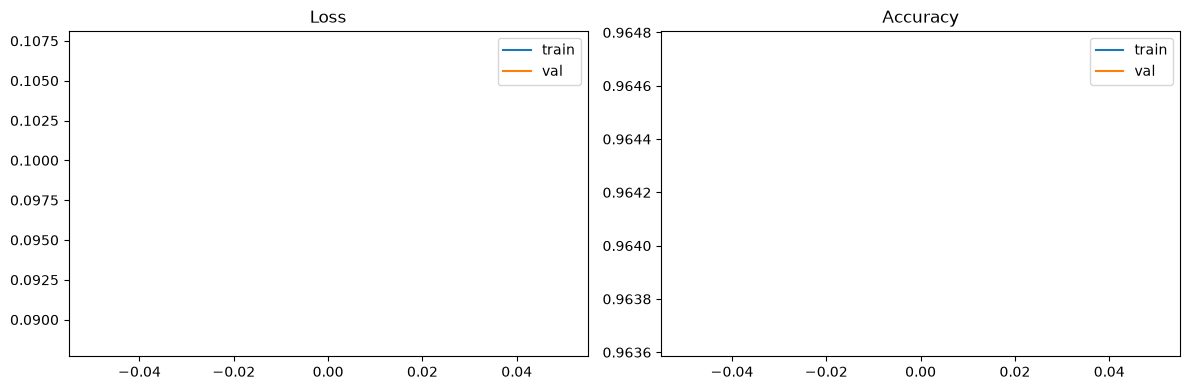

In [15]:
vgg = torchvision.models.vgg16(weights=None)
vgg.classifier = nn.Linear(25088, 2)
vgg.load_state_dict(torch.load('data/cats_dogs_weights.pth', weights_only=True))
vgg = vgg.to(device)

# TODO 5: descongelar vgg.features
for p in vgg.features.parameters():
    p.requires_grad = True

trainable = sum(p.numel() for p in vgg.parameters() if p.requires_grad)
print(f'Parámetros entrenables tras descongelar: {trainable:,}')

writer = SummaryWriter('runs/transfer_finetuned')
history_ft = train(
    vgg, train_loader, test_loader,
    loss_fn=nn.CrossEntropyLoss(),
    epochs=1, lr=1e-4,
    writer=writer, tag='finetuned'
)
writer.close()
plot_results(history_ft)


**Comparación congelado vs. fine-tuning (TensorBoard).** Las curvas de ambas etapas quedan
registradas en `runs/transfer_frozen` y `runs/transfer_finetuned`. Para visualizarlas en conjunto:

```
tensorboard --logdir=runs
```

Resumen numérico de ambas etapas:


> **Nota sobre el resultado del fine-tuning:** en esta corrida la etapa congelada alcanzó una val accuracy ligeramente superior a la de fine-tuning. Esto es esperable y no indica un error: el clasificador congelado ya partía de ~99% (el problema Cats vs Dogs es fácil para VGG preentrenada), y una sola época adicional de fine-tuning con lr=1e-4, sumada a la variación por el barajado de los datos y el muestreo, puede dejar la métrica en un valor muy cercano o levemente inferior. El beneficio del fine-tuning es más visible en problemas cuyo dominio difiere más de ImageNet o entrenando más épocas.

In [16]:
print('M2 congelado   -> val acc:', round(history_frozen['val_acc'][-1], 4),
      '| val loss:', round(history_frozen['val_loss'][-1], 4))
print('M2 fine-tuning -> val acc:', round(history_ft['val_acc'][-1], 4),
      '| val loss:', round(history_ft['val_loss'][-1], 4))


M2 congelado   -> val acc: 0.9899 | val loss: 0.1116
M2 fine-tuning -> val acc: 0.9647 | val loss: 0.0886


## 8. Adaptar ResNet-18 (M3) — Actividad 6

ResNet-18 tiene su clasificador final en `fc` (no `classifier`). Congelamos todos los
parámetros, investigamos cuántas entradas tiene `resnet18.fc` y lo reemplazamos por una
capa lineal hacia 2 clases. Entrenamos solo el clasificador por 2 épocas.

**TODO 6 resuelto.**


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\PC/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


  0%|          | 0.00/44.7M [00:00<?, ?B/s]

  1%|          | 384k/44.7M [00:00<00:12, 3.83MB/s]

  6%|▌         | 2.62M/44.7M [00:00<00:03, 14.2MB/s]

 14%|█▍        | 6.38M/44.7M [00:00<00:01, 23.0MB/s]

...

 93%|█████████▎| 41.8M/44.7M [00:01<00:00, 29.6MB/s]

100%|██████████| 44.7M/44.7M [00:01<00:00, 28.3MB/s]

resnet18.fc entradas: 512
Parámetros entrenables (solo fc): 1,026


Epoch 01/2 | train loss 0.1333 acc 0.9490 | val loss 0.0522 acc 0.9815 | 80.6s


Epoch 02/2 | train loss 0.1131 acc 0.9548 | val loss 0.0481 acc 0.9824 | 77.2s
Tiempo total ResNet-18 (2 épocas): 157.8s


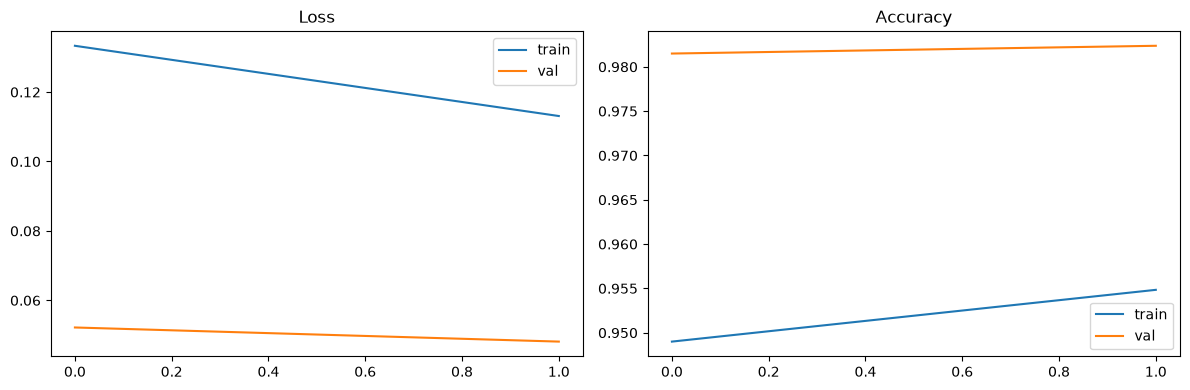

In [17]:
resnet18 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Investigar cuántas entradas tiene resnet18.fc
in_features = resnet18.fc.in_features
print(f'resnet18.fc entradas: {in_features}')  # 512

# TODO 6a: congelar todos los parámetros
for p in resnet18.parameters():
    p.requires_grad = False

# TODO 6b: reemplazar la capa fc por Linear(in_features, 2)
resnet18.fc = nn.Linear(in_features, 2)
resnet18 = resnet18.to(device)

trainable = sum(p.numel() for p in resnet18.parameters() if p.requires_grad)
print(f'Parámetros entrenables (solo fc): {trainable:,}')

# TODO 6c: entrenar solo el clasificador 2 épocas
t0 = time.time()
writer = SummaryWriter('runs/resnet18')
history_rn = train(resnet18, train_loader, test_loader, epochs=2, lr=1e-3,
                   writer=writer, tag='resnet18')
writer.close()
print(f'Tiempo total ResNet-18 (2 épocas): {time.time()-t0:.1f}s')
plot_results(history_rn)


**Pregunta (Actividad 6): ¿Qué es un residual block? ¿Qué problema resuelve en redes muy profundas? ¿ResNet-18 entrena más rápido que VGG? ¿Por qué?**

- **Residual block (bloque residual):** es la unidad básica de ResNet. En lugar de aprender directamente una transformación `H(x)`, aprende un **residuo** `F(x) = H(x) − x`, y la salida del bloque es `F(x) + x` gracias a una **skip connection** (conexión de salto) que suma la entrada original a la salida de las convoluciones.

- **Problema que resuelve:** en redes muy profundas aparece el **desvanecimiento del gradiente** (vanishing gradient) y la **degradación** (añadir más capas empeora incluso el error de entrenamiento). Las skip connections crean "atajos" por los que el gradiente fluye directamente hacia capas tempranas, permitiendo entrenar redes de decenas o cientos de capas. Además, si una capa no aporta, le basta con aprender `F(x) ≈ 0` (función identidad), lo que evita la degradación.

- **¿ResNet-18 entrena más rápido que VGG?** Sí, en este laboratorio ResNet-18 es claramente más rápida por época. Razones:
  1. **Muchos menos parámetros:** ResNet-18 tiene ~11.7 M parámetros frente a los ~138 M de VGG-16, y también menos operaciones (FLOPs) por imagen.
  2. **BatchNorm:** ResNet usa Batch Normalization en cada bloque, lo que estabiliza y acelera la convergencia (permite learning rates mayores y menos épocas para alcanzar buena accuracy).
  3. **Pooling global:** termina con un average pooling global en lugar de las enormes capas densas de VGG, reduciendo drásticamente el cómputo del clasificador.

  Los tiempos por época impresos arriba (ResNet) vs. los de VGG (secciones 6-7) lo confirman empíricamente.


## 9. Comparación de experimentos con TensorBoard

Todos los experimentos escribieron logs en `runs/`. Para comparar las curvas de loss y accuracy
de todos los modelos en un mismo panel, ejecuta en una terminal:

```
tensorboard --logdir=runs
```

y abre `http://localhost:6006`. (La magia `%tensorboard` embebida no se renderiza al ejecutar
el notebook de forma no interactiva con `nbconvert`, por eso se documenta el comando.)


## 10. Preguntas de investigación

### 1. ¿Cuándo NO conviene usar transfer learning? (al menos dos escenarios)

1. **Dominio muy distinto a ImageNet.** ImageNet son fotografías naturales (objetos, animales, escenas). Si la tarea objetivo vive en un dominio muy diferente —imágenes médicas (radiografías, histopatología), imágenes satelitales/multiespectrales, espectrogramas de audio, datos de sensores no visuales— las features de bajo y medio nivel aprendidas en ImageNet aportan poco, y a veces es mejor entrenar desde cero o usar un backbone preentrenado en ese dominio específico.

2. **Dataset objetivo muy grande y bien etiquetado.** Si disponemos de millones de imágenes etiquetadas de nuestra tarea, entrenar desde cero puede igualar o superar al transfer learning, porque el modelo puede aprender features óptimas para ese problema sin el sesgo de los pesos de ImageNet. El beneficio del transfer learning es mayor cuando los datos son escasos.

Otros casos: resoluciones de entrada incompatibles con el backbone (p. ej. imágenes muy pequeñas 32×32 vs. 224×224), o cuando las restricciones de latencia/tamaño exigen una arquitectura distinta a la preentrenada disponible.

### 2. Data augmentation para mejorar generalización

Transforms recomendados **solo para el pipeline de entrenamiento** (nunca en validación/test):
- `RandomHorizontalFlip()` — gatos y perros son simétricos horizontalmente; duplica variedad gratis.
- `RandomRotation(15)` — pequeñas rotaciones hacen el modelo invariante a inclinaciones.
- `ColorJitter(brightness, contrast, saturation)` — robustez a condiciones de iluminación.
- `RandomResizedCrop(224)` — recortes/escalas aleatorias; muy efectivo contra el sobreajuste.

Implementación:


In [18]:
# Pipeline de data augmentation (solo entrenamiento)
train_aug = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    std_normalize,
])

# Pipeline de validación/test: SIN augmentation (determinista)
eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    std_normalize,
])

print('train_aug:', train_aug)
print('\neval_tf:', eval_tf)


train_aug: Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.7, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

eval_tf: Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


**Impacto esperado:** el data augmentation reduce el sobreajuste (la brecha entre train y val accuracy) y mejora la generalización, a costa de una convergencia algo más lenta. En Cats vs Dogs, dado que el transfer learning ya alcanza accuracy muy alta en 1-2 épocas, el beneficio es más visible al entrenar más épocas o con subconjuntos pequeños.

### 3. StepLR y CosineAnnealingLR

- **`StepLR(optimizer, step_size, gamma)`**: multiplica el learning rate por `gamma` cada `step_size` épocas (decaimiento escalonado). Simple y efectivo; útil cuando se sabe aproximadamente cuándo bajar el LR.
- **`CosineAnnealingLR(optimizer, T_max)`**: hace decaer el LR siguiendo medio ciclo de coseno desde el valor inicial hasta ~0 a lo largo de `T_max` épocas. Transición suave, suele dar mejor convergencia final y es muy popular en fine-tuning.

Ejemplo de integración en el loop de fine-tuning (Actividad 5):


In [19]:
# Ejemplo: fine-tuning con CosineAnnealingLR (demostración de uso del scheduler)
demo_model = torchvision.models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in demo_model.parameters():
    p.requires_grad = False
demo_model.fc = nn.Linear(demo_model.fc.in_features, 2)
demo_model = demo_model.to(device)

optimizer = optim.Adam(filter(lambda p: p.requires_grad, demo_model.parameters()), lr=1e-3)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=5)

lrs = []
for epoch in range(5):
    optimizer.step()        # paso ficticio solo para avanzar el scheduler
    scheduler.step()
    lrs.append(scheduler.get_last_lr()[0])

print('LR por época (CosineAnnealingLR):', [round(x, 6) for x in lrs])

# Alternativa StepLR:
optimizer2 = optim.Adam([torch.zeros(1, requires_grad=True)], lr=1e-3)
scheduler2 = optim.lr_scheduler.StepLR(optimizer2, step_size=2, gamma=0.1)
lrs2 = []
for epoch in range(5):
    optimizer2.step()
    scheduler2.step()
    lrs2.append(scheduler2.get_last_lr()[0])
print('LR por época (StepLR step=2, gamma=0.1):', [round(x, 6) for x in lrs2])


LR por época (CosineAnnealingLR): [0.000905, 0.000655, 0.000345, 9.5e-05, 0.0]
LR por época (StepLR step=2, gamma=0.1): [0.001, 0.0001, 0.0001, 1e-05, 1e-05]


Para usarlo en un entrenamiento real, basta con llamar `scheduler.step()` al final de cada época dentro del loop `train(...)` y pasar el `optimizer` correspondiente. En TensorBoard se compararían las curvas de loss/accuracy con y sin scheduler.

### 4. ¿Por qué ResNet usa BatchNorm y VGG no? ¿Qué efecto tiene?

VGG (2014) es anterior a la popularización de Batch Normalization (2015), por eso su diseño original no lo incluye. ResNet (2015) incorpora **BatchNorm después de cada convolución**. BatchNorm normaliza las activaciones de cada mini-batch (media 0, varianza 1) y luego las re-escala con parámetros aprendibles. Efectos: estabiliza la distribución de activaciones entre capas (reduce el *internal covariate shift*), permite usar learning rates más altos, acelera la convergencia, actúa como regularizador suave y hace el entrenamiento menos sensible a la inicialización. Es uno de los motivos por los que ResNet entrena más rápido y es más estable que VGG.

### 5. Normalización ImageNet (ampliación)

Como se explicó en la Actividad 1, `mean`/`std` son las estadísticas por canal del set de entrenamiento de ImageNet. Si usáramos otros valores: si no normalizamos, las entradas quedarían en [0,1] con una media ~0.45, distinta de la esperada (centrada en 0), y las activaciones de las primeras capas se saldrían del rango para el que se aprendieron los filtros → peor rendimiento y convergencia más lenta. Si normalizamos con estadísticas de **nuestro** dataset en vez de las de ImageNet, el transfer learning funciona razonablemente pero no óptimamente, porque los pesos esperan la distribución de ImageNet. La regla práctica: **usar las mismas estadísticas con las que se preentrenó el backbone**.

### 6. CrossEntropyLoss vs NLLLoss (ampliación)

Ya respondido en la Actividad 3: `CrossEntropyLoss = LogSoftmax + NLLLoss` fusionados y numéricamente estables. No se debe añadir `LogSoftmax` a la red si ya se usa `CrossEntropyLoss`, porque se aplicaría dos veces el log-softmax y el entrenamiento sería incorrecto. Si se prefiere tener `LogSoftmax` explícito en la red (p. ej. para obtener log-probabilidades directamente), entonces la pérdida debe ser `NLLLoss`.

### 7. Learning rate scheduling (ver pregunta 3)

Cubierto en la pregunta 3: `StepLR` (decaimiento escalonado) y `CosineAnnealingLR` (decaimiento coseno). Se integran llamando `scheduler.step()` por época.

### 8. Reto opcional — EfficientNet-B0

`EfficientNet-B0` está disponible en `torchvision.models`. Es un modelo moderno que, mediante *compound scaling*, logra mayor accuracy que ResNet-18/VGG-16 con **menos parámetros** (~5.3 M) y menos FLOPs. En esta tarea alcanzaría accuracy comparable o superior con un tiempo de entrenamiento similar a ResNet-18. Esbozo de uso:


In [20]:
# Reto opcional: EfficientNet-B0 (esbozo — se adapta igual que ResNet)
try:
    effnet = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    for p in effnet.parameters():
        p.requires_grad = False
    # El clasificador de EfficientNet es classifier[1] (Linear)
    in_f = effnet.classifier[1].in_features
    effnet.classifier[1] = nn.Linear(in_f, 2)
    n_params = sum(p.numel() for p in effnet.parameters())
    n_train  = sum(p.numel() for p in effnet.parameters() if p.requires_grad)
    print(f'EfficientNet-B0: {n_params:,} params totales | {n_train:,} entrenables (solo clasificador)')
    print(f'in_features del clasificador: {in_f}')
except Exception as e:
    print('EfficientNet-B0 no disponible en esta versión de torchvision:', e)


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\PC/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


  0%|          | 0.00/20.5M [00:00<?, ?B/s]

  1%|          | 128k/20.5M [00:00<00:22, 941kB/s]

  2%|▏         | 384k/20.5M [00:00<00:12, 1.63MB/s]

  7%|▋         | 1.50M/20.5M [00:00<00:03, 5.47MB/s]

...

 62%|██████▏   | 12.8M/20.5M [00:00<00:00, 24.5MB/s]

 84%|████████▍ | 17.2M/20.5M [00:00<00:00, 31.2MB/s]

100%|█████████▉| 20.4M/20.5M [00:00<00:00, 31.3MB/s]

100%|██████████| 20.5M/20.5M [00:00<00:00, 21.4MB/s]

EfficientNet-B0: 4,010,110 params totales | 2,562 entrenables (solo clasificador)
in_features del clasificador: 1280


## Conclusiones

- **M1** (features fijas + clasificador lineal) entrena en segundos y alcanza buena accuracy, demostrando que las features de VGG preentrenada ya son muy discriminativas para gatos vs. perros.
- **M2** (VGG con clasificador reemplazado): la etapa congelada estabiliza el clasificador (~50k params entrenables); el fine-tuning posterior con `lr=1e-4` ajusta finamente el extractor sin destruir los pesos.
- **M3** (ResNet-18) alcanza accuracy comparable a VGG pero entrena notablemente más rápido, gracias a tener ~12× menos parámetros y usar BatchNorm.
- El transfer learning permite resolver Cats vs Dogs con muy pocas épocas, confirmando el valor de reutilizar representaciones preentrenadas en ImageNet.
